# PBL-3: Ensemble learning for video moment retrieval

Task: decide whether each second of a video answers a query (`rel_binary`) from 31 engineered features (Review 1 feature table). Every number below is a **held-out** result: leave-one-video-out over 9 NASA videos, with grouped inner cross-validation for CART depth, stacking, BMA weights, output smoothing and thresholds.

Rubric: problem & dataset (4) · ensemble implementation (8) · comparative analysis (4) · interpretation & presentation (4).

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.precision', 3)
RERUN = False  # True: refit all folds (about 10 minutes with 9 cores)
if RERUN:
    from cmvs.config import load_config
    from analysis.ensemble import run_ensemble
    run_ensemble(load_config('config.yaml'))
OUT = ROOT / 'results' / 'ensemble'
FIG = OUT / 'figures'

## 1. Problem and dataset

In [2]:
data = pd.read_csv('results/ml/dataset.csv.gz')
print(f'{len(data):,} rows | {data.video_id.nunique()} videos | {data.query_id.nunique()} queries | '
      f'{data.rel_binary.mean():.1%} relevant')
from analysis.features import FEATURES
print(len(FEATURES), 'features:', ', '.join(FEATURES))

28,900 rows | 9 videos | 86 queries | 8.3% relevant
31 features: visual_raw, speech_raw, visual_norm, speech_norm, fused_baseline, visual_z, speech_z, visual_rank, speech_rank, visual_smooth, speech_smooth, frame_change, in_speech, rel_pos, query_words, visual_near, speech_near, visual_wide, speech_wide, fused_smooth, fused_near, visual_peak_dist, speech_peak_dist, fused_peak_dist, visual_vs_peak, speech_vs_peak, fused_vs_peak, local_rank_fused, scene_cuts_near, keyword_overlap, keyword_overlap_near


## 2. Ensemble implementations (`analysis/ensemble.py`)

| Method | Idea |
|---|---|
| CART tree | single Gini tree, depth by inner CV |
| Bagging | 300 bootstrap trees averaged (variance reduction) |
| Random forest / Extra trees | bagging + random features / random thresholds |
| AdaBoost (SAMME) | 300 re-weighted depth-2 trees (bias reduction) |
| Hist. gradient boosting | 300 trees fitted to log-loss gradients |
| Soft voting | mean probability of logistic, RF, HGB |
| Stacking | logistic meta-learner on out-of-fold log-odds of 8 learners |
| Bayesian model averaging | pseudo-BMA+ weights from out-of-fold log score, Bayesian bootstrap |

In [3]:
from cmvs.config import load_config
from analysis.ensemble import make_learner, LEARNERS
cfg = load_config('config.yaml')
for key in LEARNERS:
    print(f'{key:18s}', make_learner(key, cfg.ensemble, cfg.ml.seed, depth=4))

logistic           Pipeline(steps=[('scale', StandardScaler()),
                ('model',
                 LogisticRegression(C=0.1, max_iter=2000, random_state=42))])
knn                Pipeline(steps=[('scale', StandardScaler()),
                ('model', KNeighborsClassifier(n_jobs=1, n_neighbors=151))])
cart               DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42)
bagging            BaggingClassifier(estimator=DecisionTreeClassifier(min_samples_leaf=5,
                                                   random_state=42),
                  n_estimators=300, n_jobs=1, random_state=42)
random_forest      RandomForestClassifier(min_samples_leaf=5, n_estimators=300, n_jobs=1,
                       random_state=42)
extra_trees        ExtraTreesClassifier(min_samples_leaf=5, n_estimators=300, n_jobs=1,
                     random_state=42)
adaboost           AdaBoostClassifier(algorithm='SAMME',
                   estimator=DecisionTreeClassifier(max_depth=2

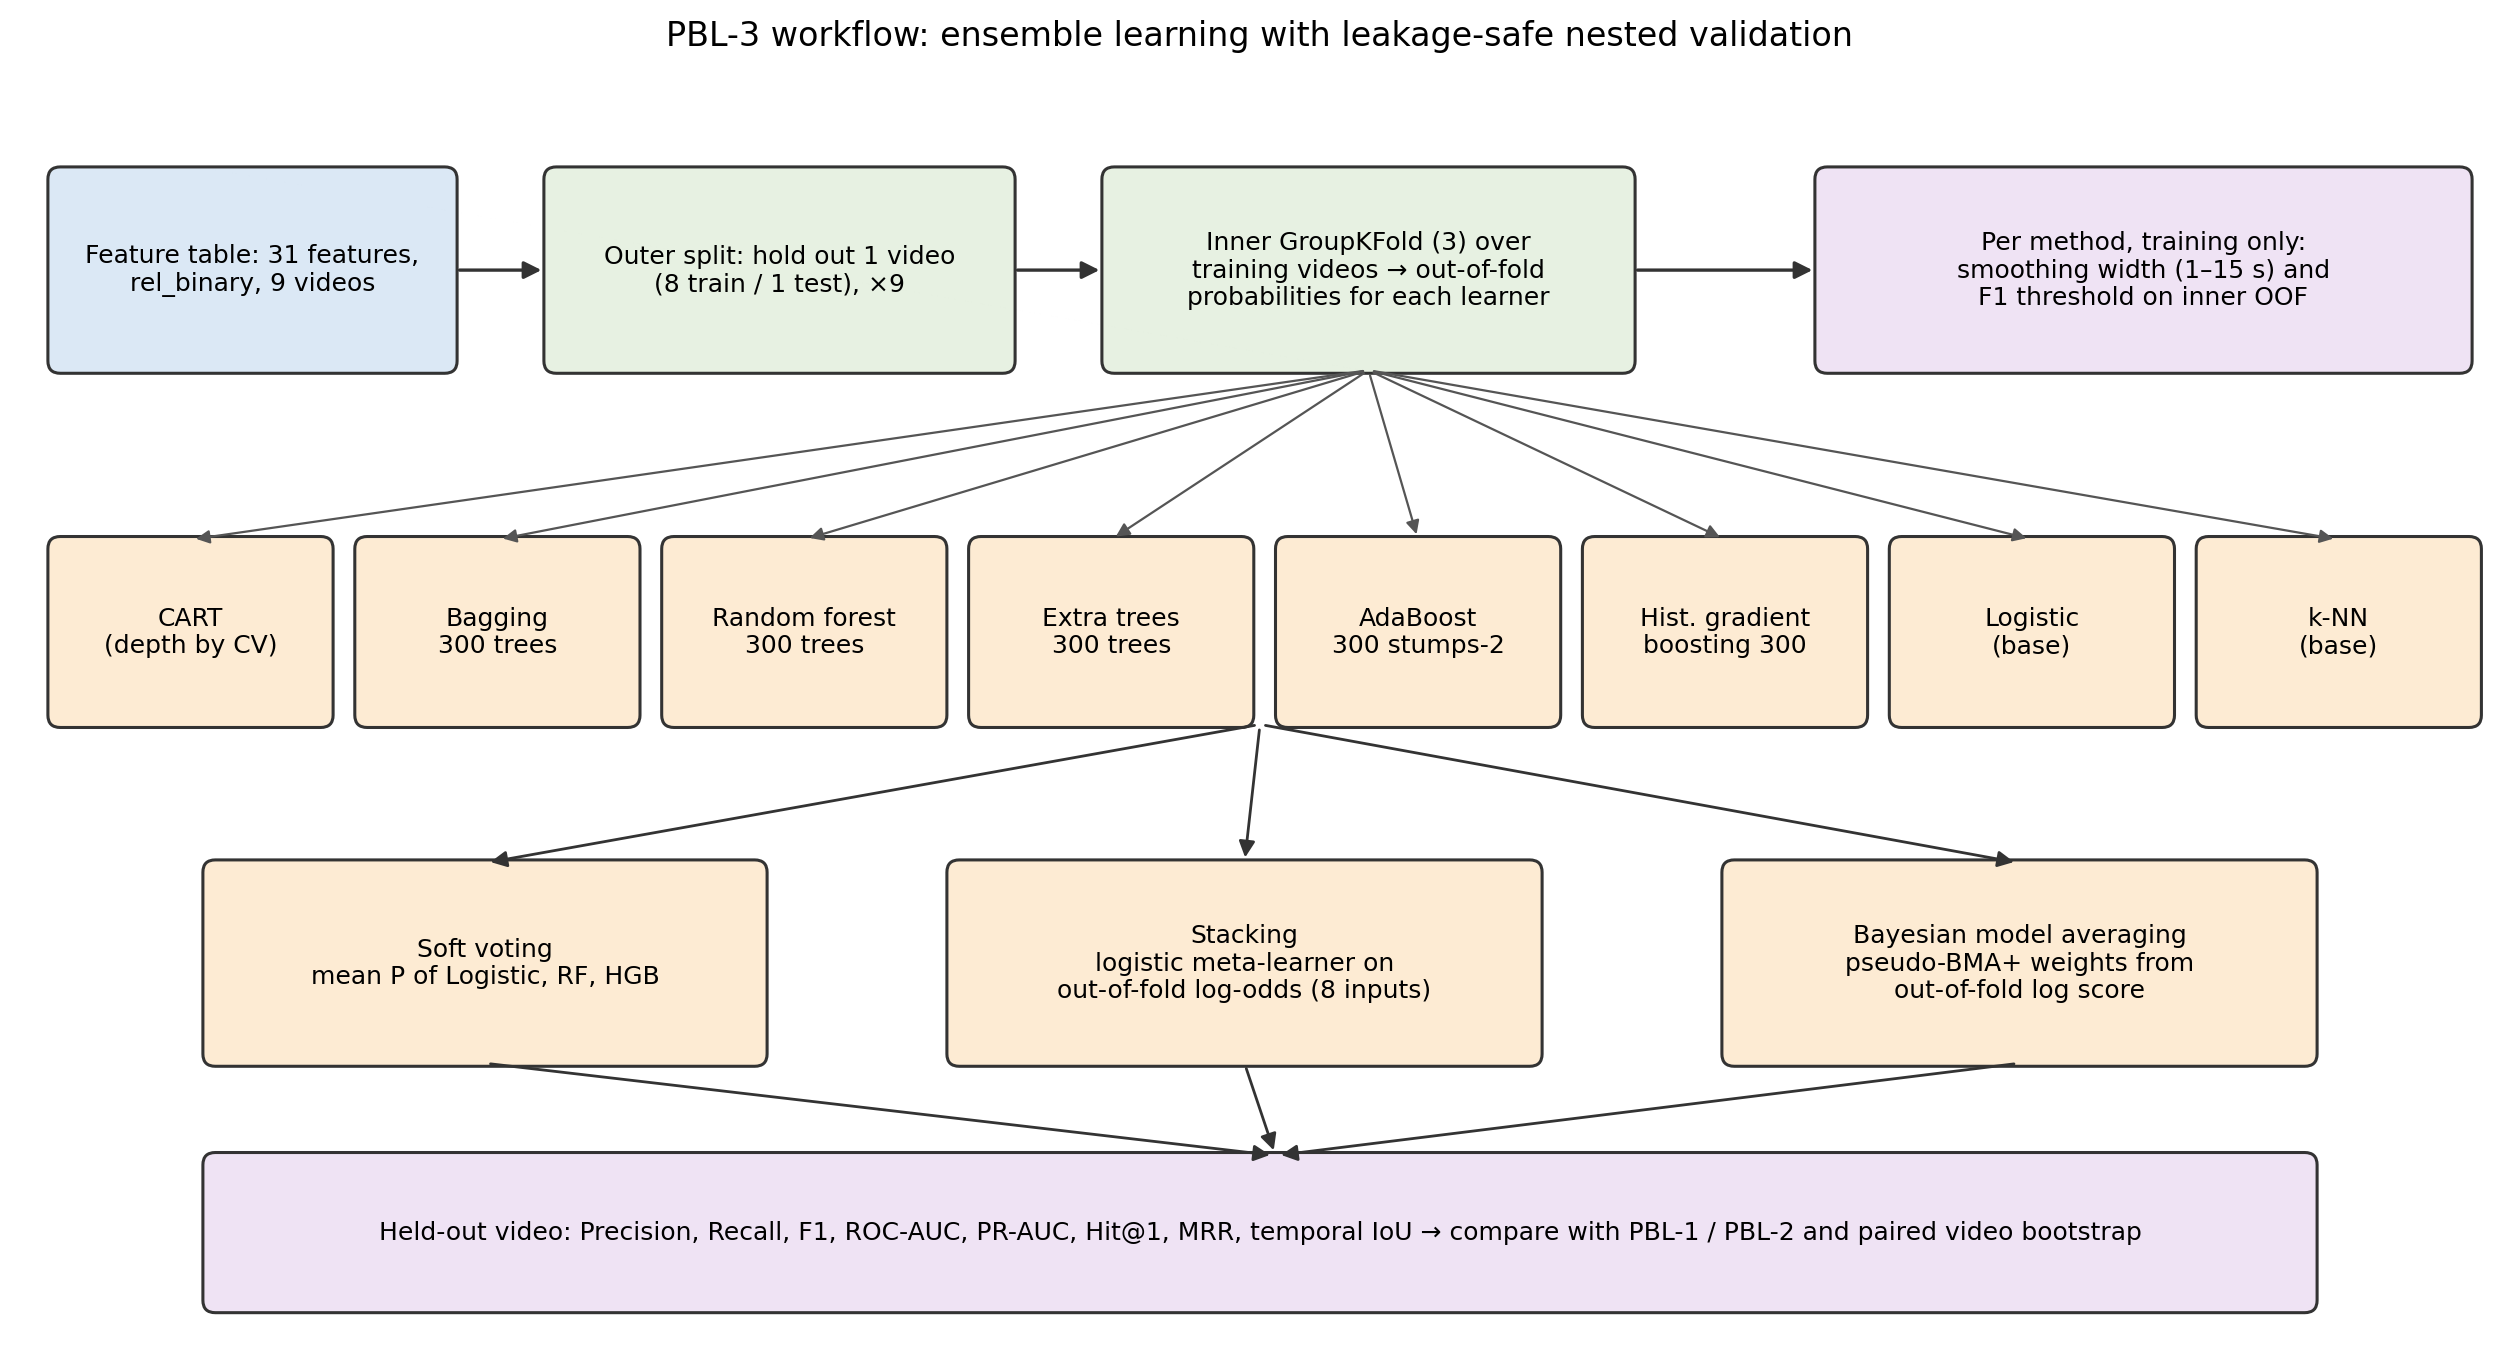

In [4]:
display(Image(str(ROOT / 'results/report/figures/workflow_pbl3.png'), width=900))

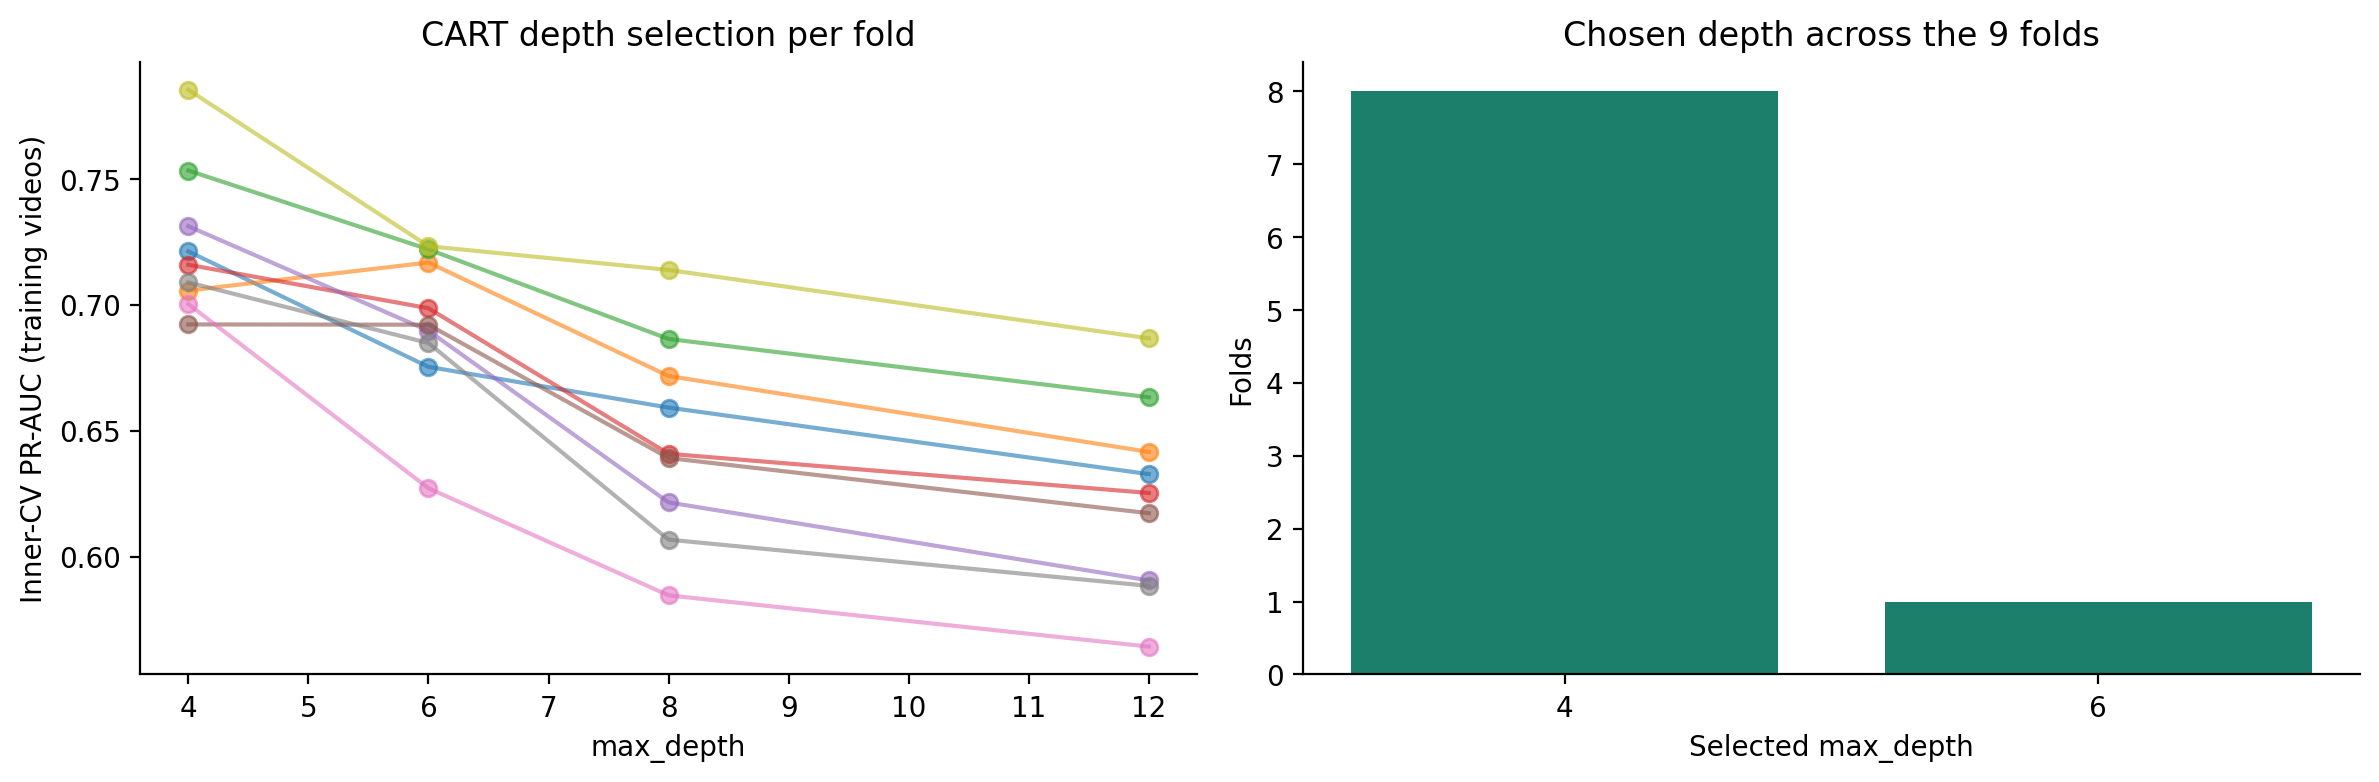

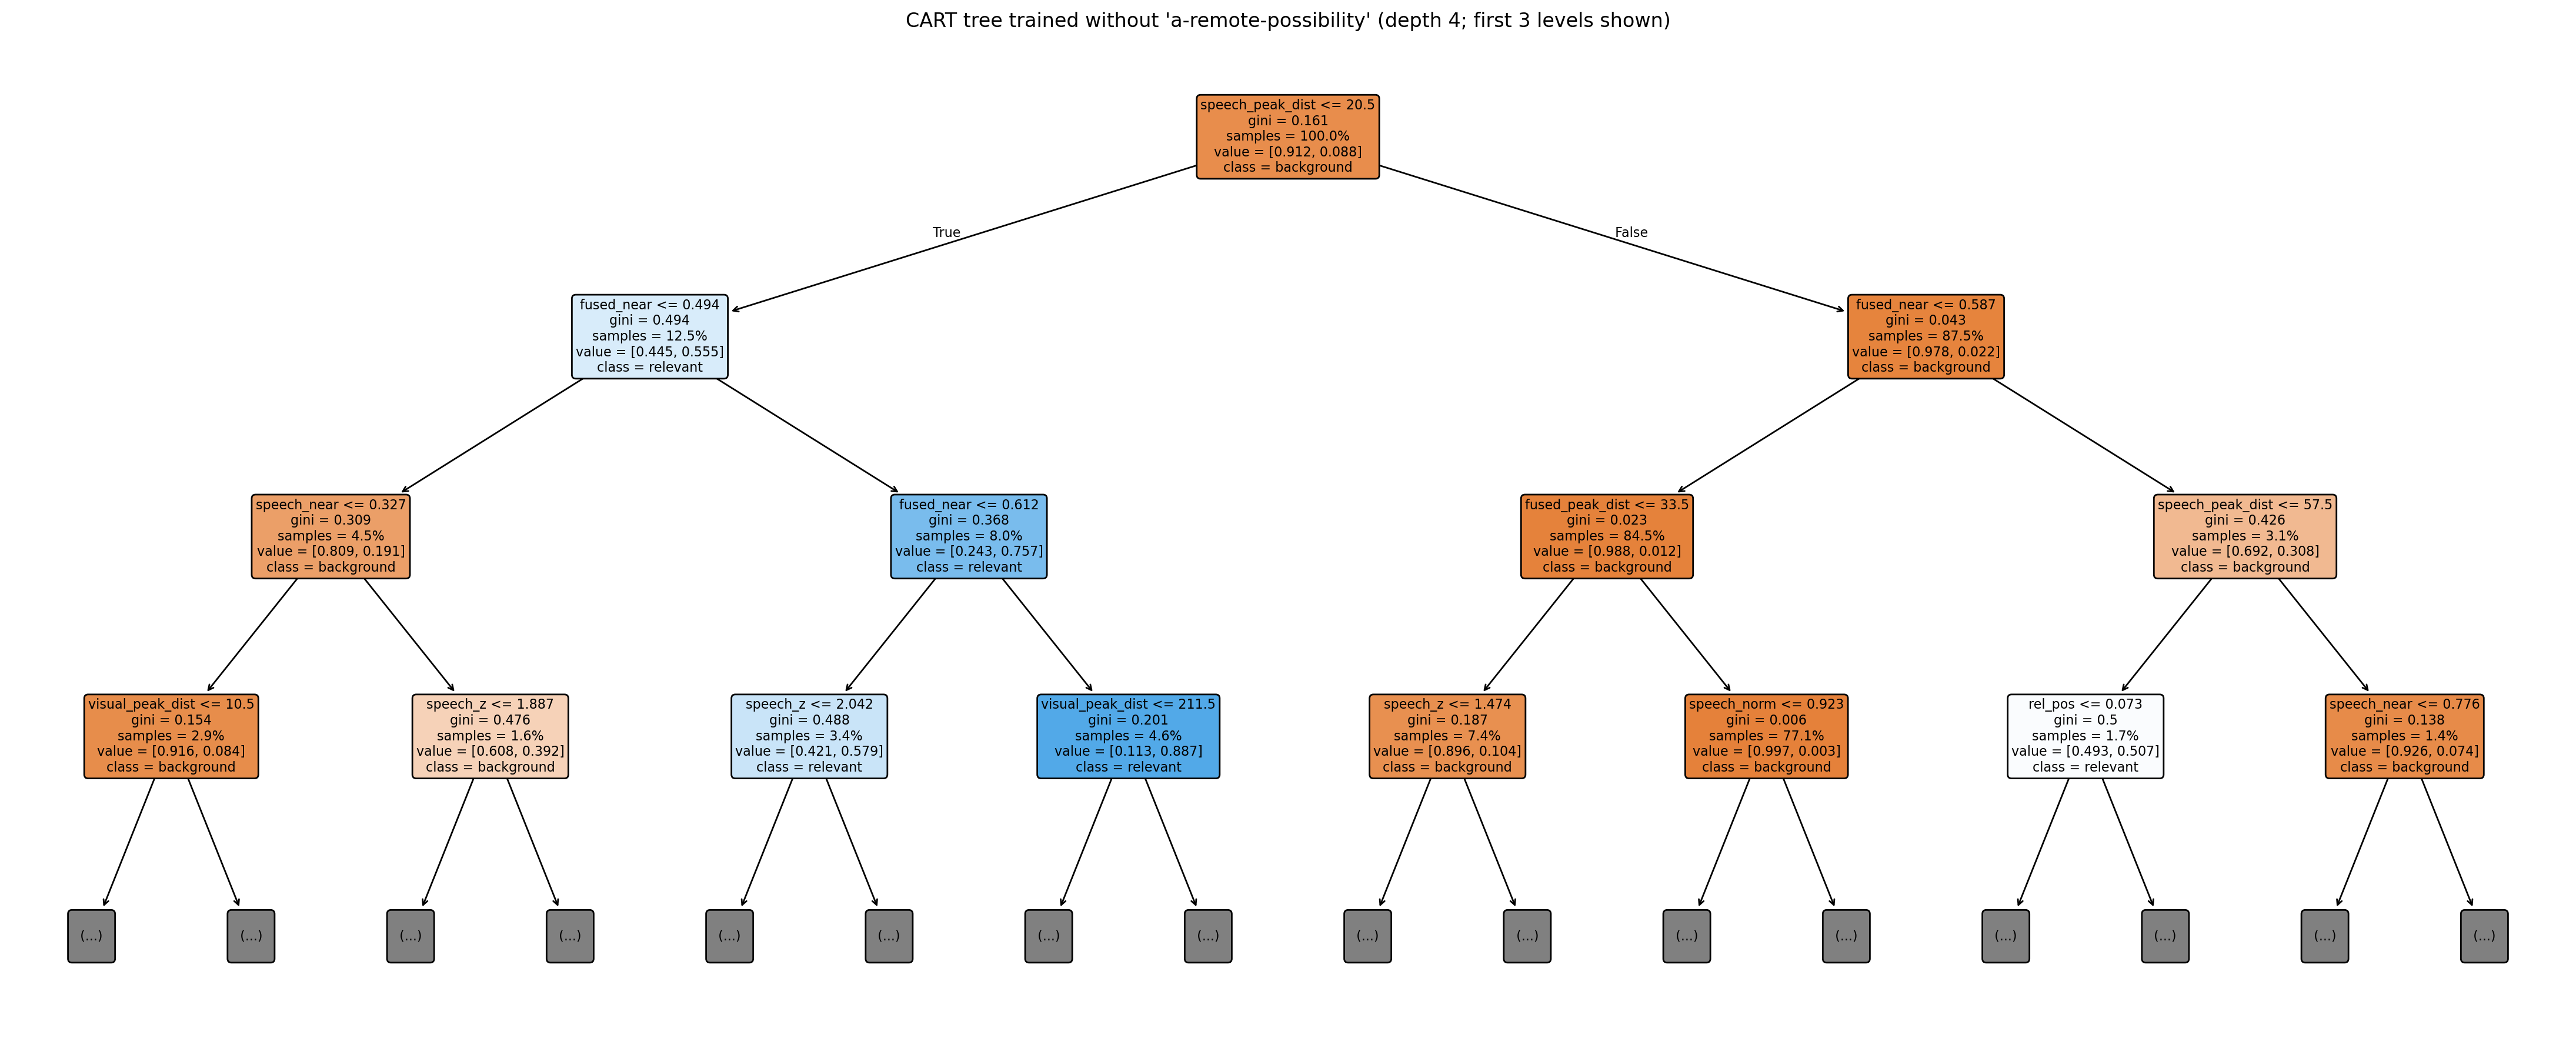

In [5]:
display(Image(str(FIG / '03_cart_depth.png'), width=800))
display(Image(str(FIG / '04_cart_tree.png'), width=1000))

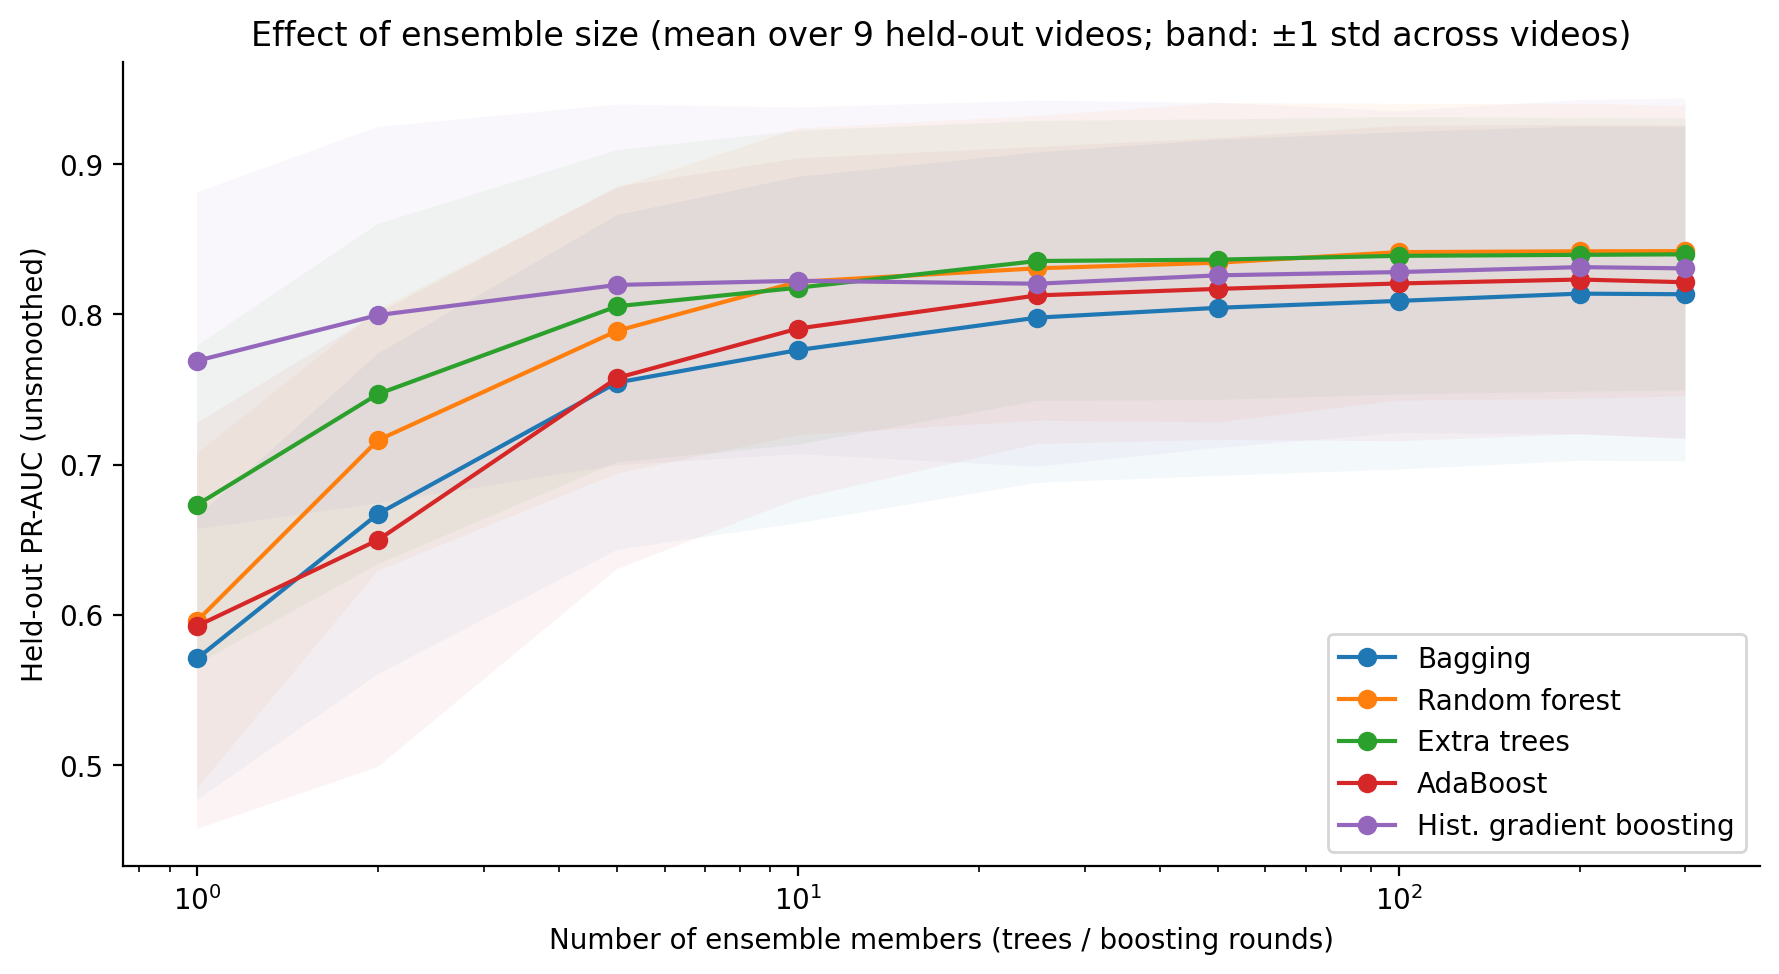

In [6]:
display(Image(str(FIG / '02_ensemble_size.png'), width=750))

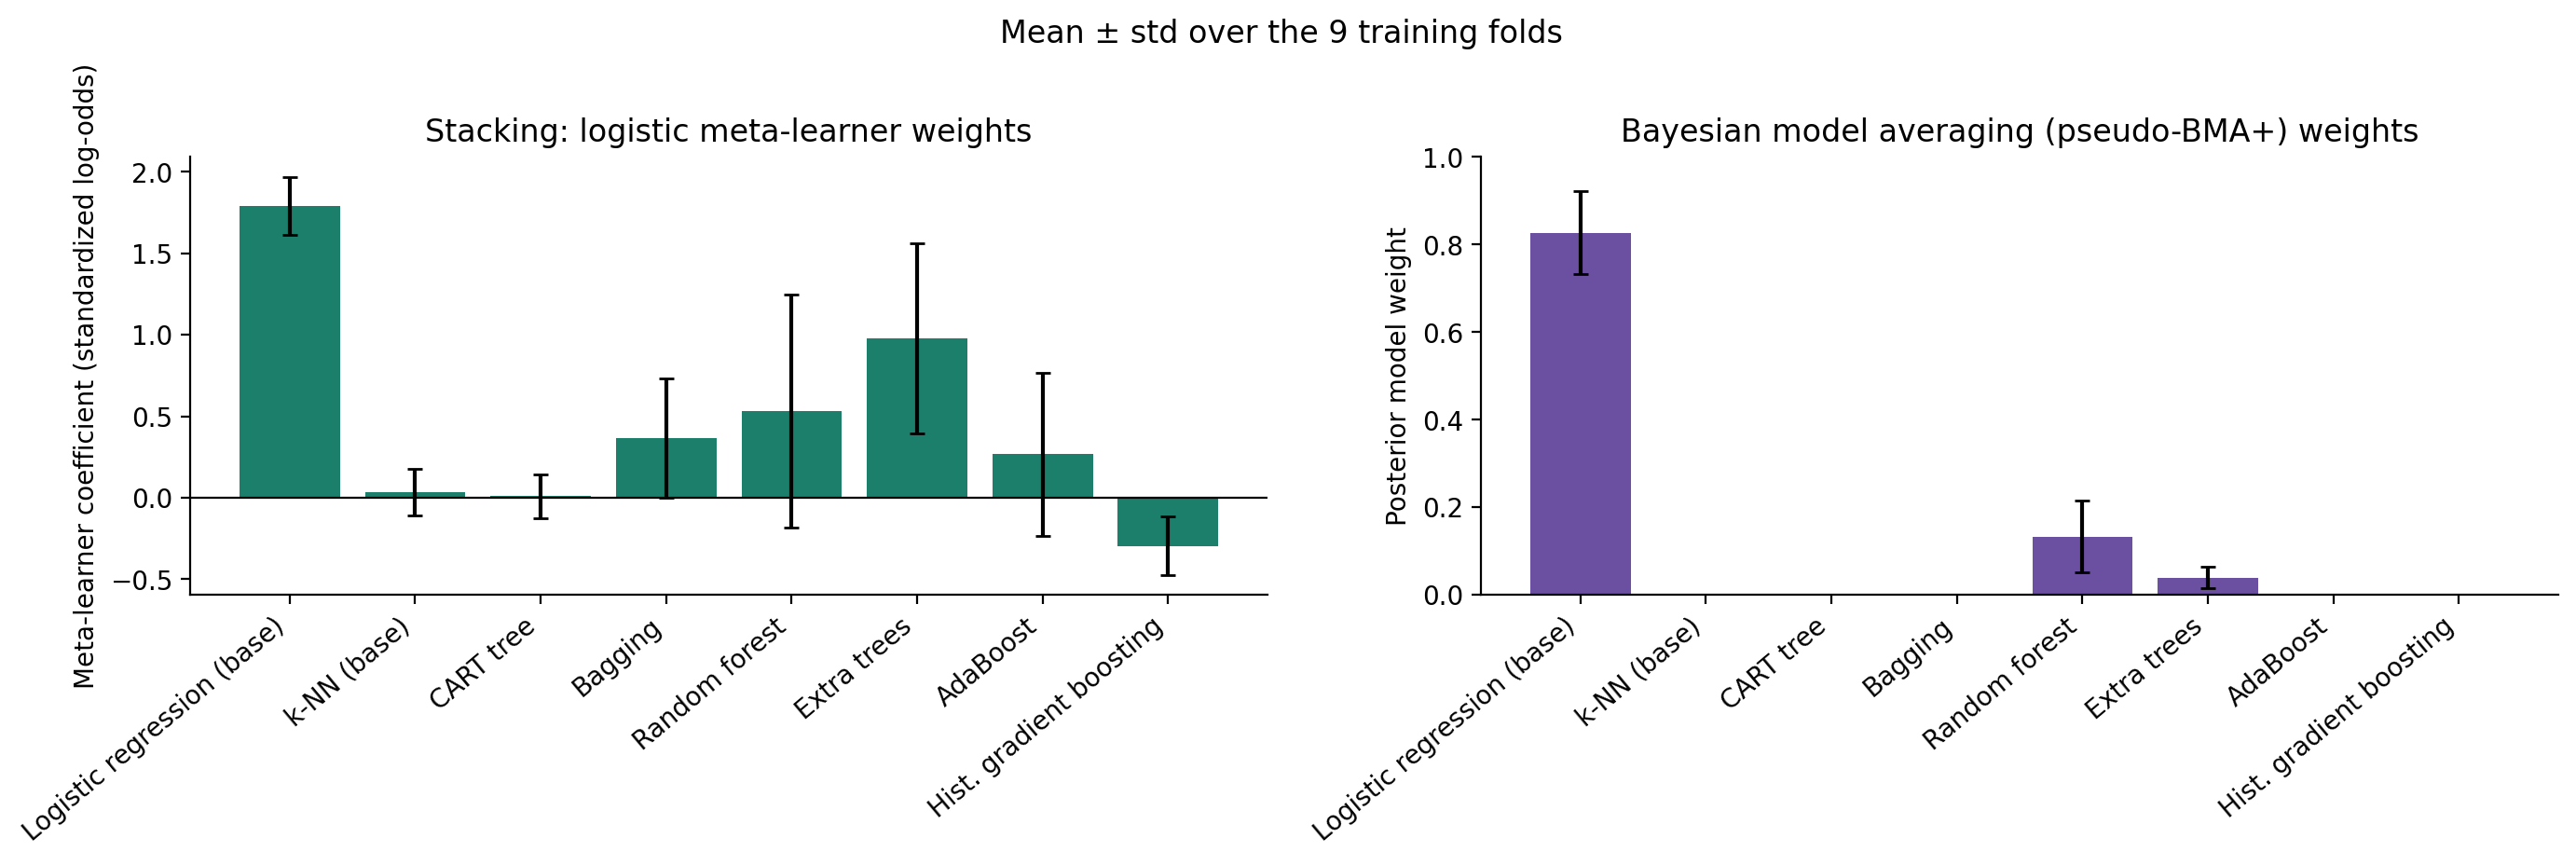

In [7]:
display(Image(str(FIG / '06_combiner_weights.png'), width=1000))

## 3. Comparative performance analysis (same folds and metrics as Reviews 1 and 2)

In [8]:
summary = pd.read_csv(OUT / 'comparison.csv')
cols = ['method','precision','recall','f1','f1_lo','f1_hi','pr_auc','roc_auc','hit_at_1','mrr','temporal_iou']
summary[cols].sort_values('f1', ascending=False).reset_index(drop=True)

,method,precision,recall,f1,f1_lo,f1_hi,pr_auc,roc_auc,hit_at_1,mrr,temporal_iou
0,Bayesian model averaging,0.744,0.814,0.771,0.718,0.818,0.853,0.982,0.938,0.947,0.637
1,Stacking,0.760,0.779,0.765,0.715,0.811,0.846,0.981,0.923,0.932,0.633
2,Soft voting,0.707,0.841,0.763,0.704,0.816,0.852,0.982,0.938,0.946,0.632
3,Logistic regression,0.728,0.811,0.761,0.709,0.810,0.845,0.978,0.944,0.948,0.626
4,CART tree,0.726,0.808,0.761,0.704,0.814,0.796,0.966,0.915,0.923,0.628
5,Extra trees,0.719,0.814,0.761,0.713,0.809,0.836,0.978,0.930,0.937,0.631
6,Random forest,0.714,0.816,0.755,0.697,0.807,0.839,0.979,0.938,0.942,0.628
7,Hist. gradient boosting,0.700,0.826,0.752,0.698,0.801,0.821,0.979,0.952,0.953,0.622
8,Bagging,0.720,0.791,0.749,0.690,0.802,0.816,0.977,0.930,0.938,0.620
9,AdaBoost,0.729,0.786,0.748,0.679,0.808,0.830,0.979,0.930,0.940,0.617


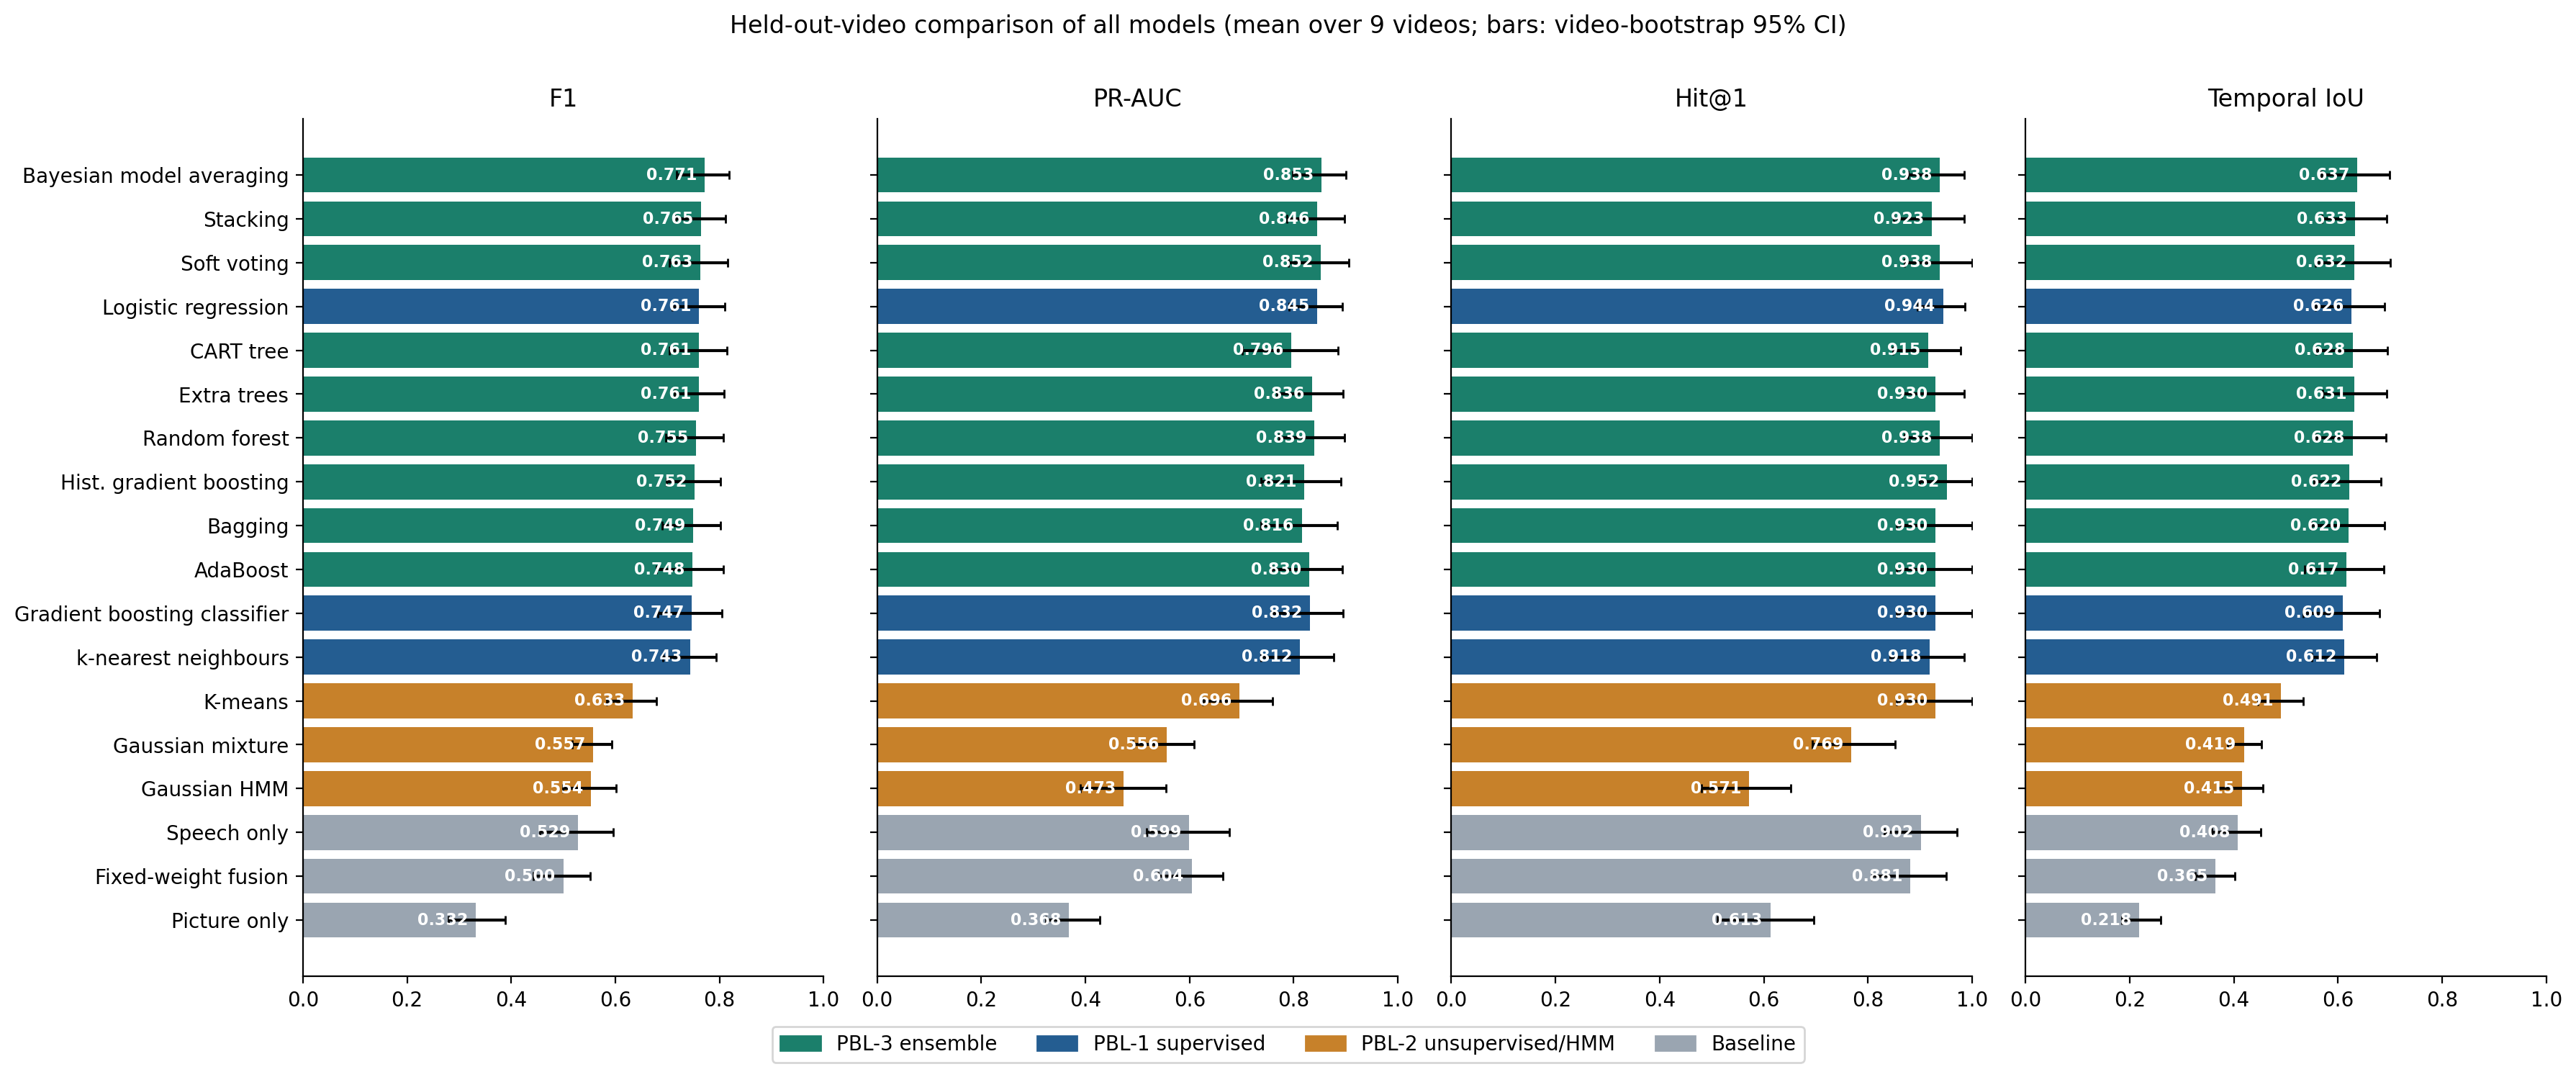

In [9]:
display(Image(str(FIG / '01_comparison.png'), width=1000))

In [10]:
paired = pd.read_csv(OUT / 'paired_vs_logistic.csv')
paired.pivot(index='method', columns='metric', values='mean_diff').round(3)

metric,f1,hit_at_1,pr_auc,temporal_iou
method,,,,
AdaBoost,-0.013,-0.014,-0.015,-0.009
Bagging,-0.012,-0.014,-0.030,-0.006
Bayesian model averaging,0.010,-0.006,0.008,0.011
CART tree,-0.000,-0.029,-0.050,0.002
Extra trees,-0.000,-0.014,-0.010,0.005
Hist. gradient boosting,-0.009,0.007,-0.025,-0.004
Random forest,-0.006,-0.006,-0.006,0.002
Soft voting,0.002,-0.006,0.006,0.006
Stacking,0.004,-0.021,0.000,0.008


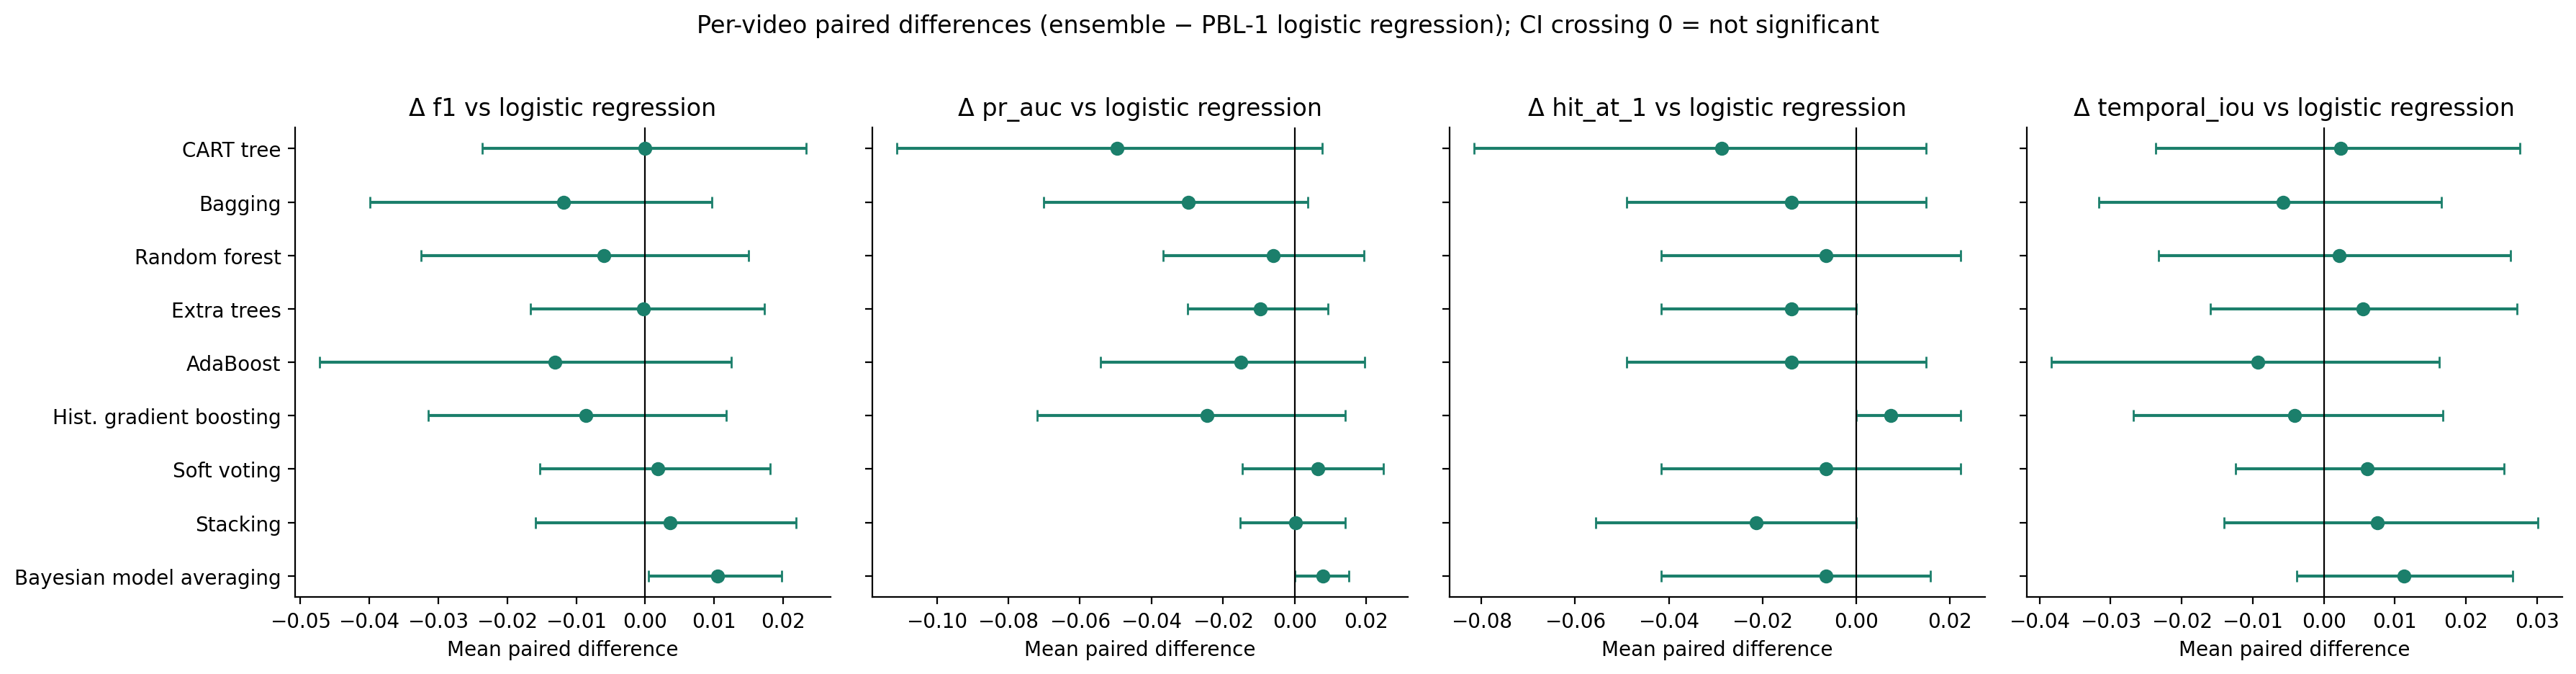

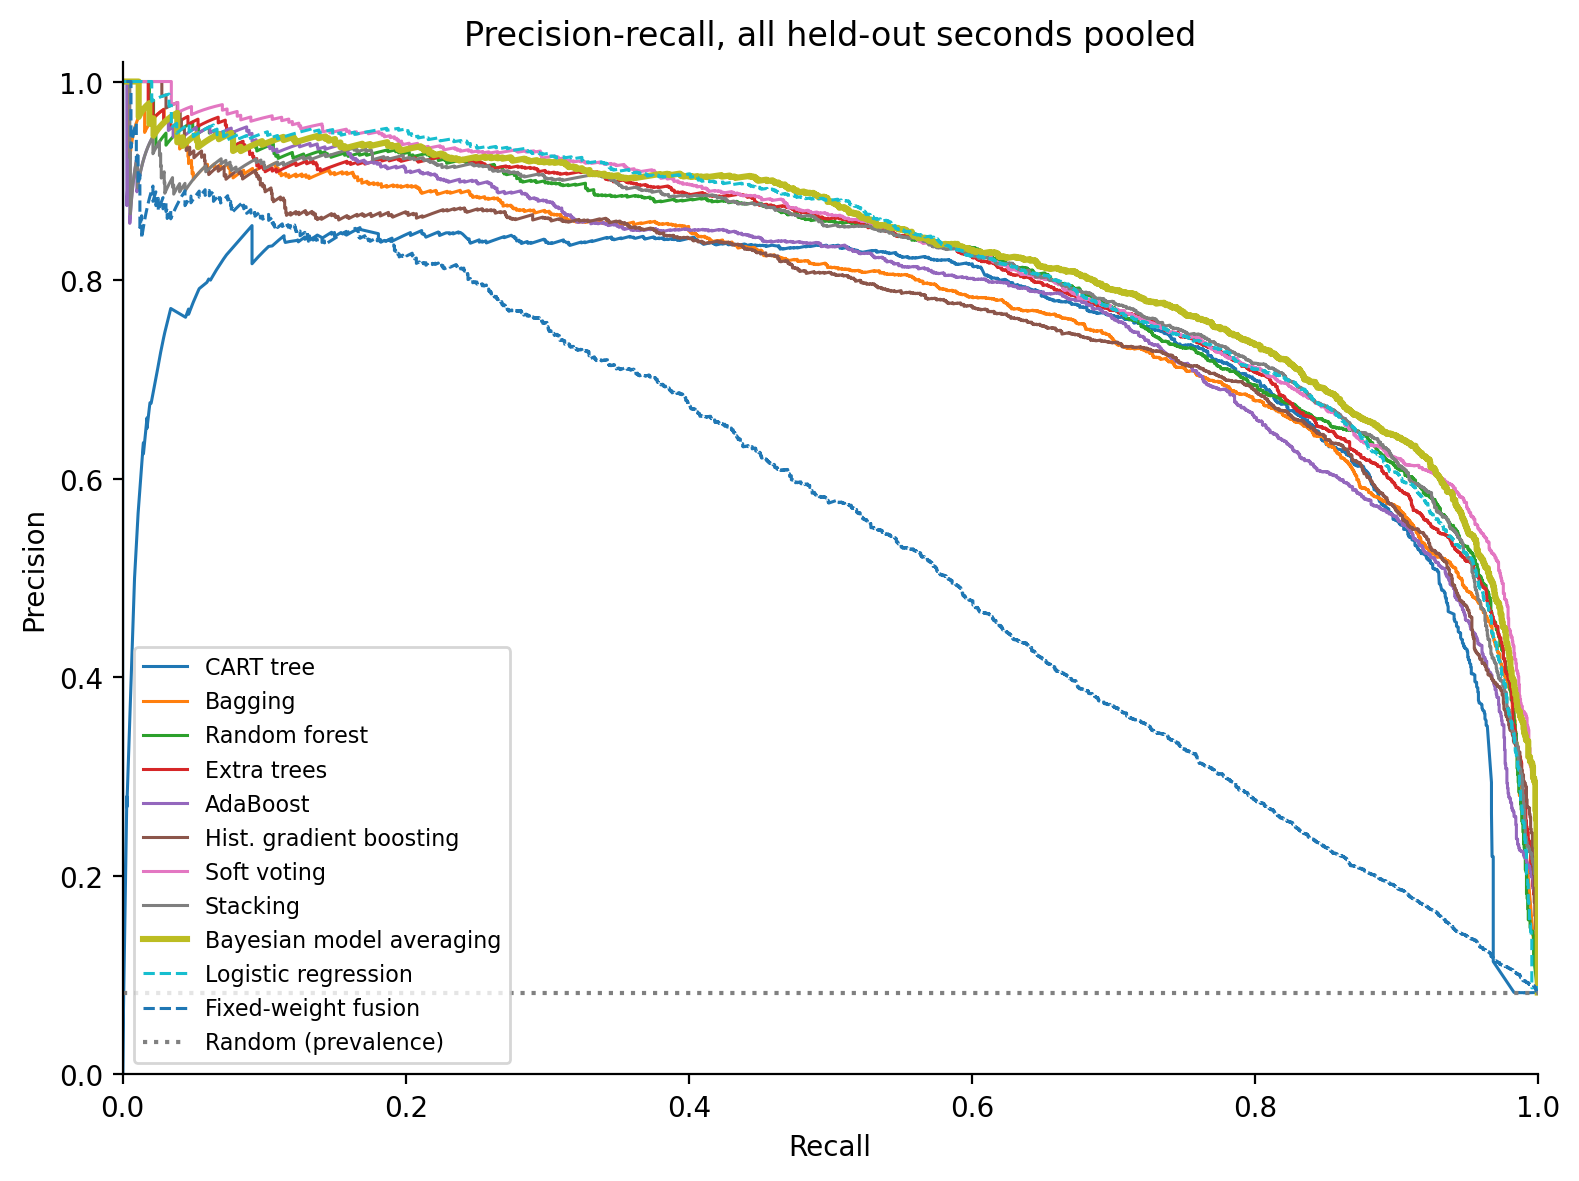

In [11]:
display(Image(str(FIG / '09_paired_differences.png'), width=1000))
display(Image(str(FIG / '08_pr_curves.png'), width=600))

,learner,fit_s,predict_s
0,AdaBoost,31.765,3.697e-02
1,Bagging,89.590,6.379e-02
2,CART tree,0.230,2.796e-04
3,Extra trees,2.626,5.256e-02
4,Hist. gradient boosting,1.413,2.644e-02
5,Logistic regression (base),0.041,4.739e-04
6,Random forest,16.850,3.712e-02
7,k-NN (base),0.009,3.330e-01


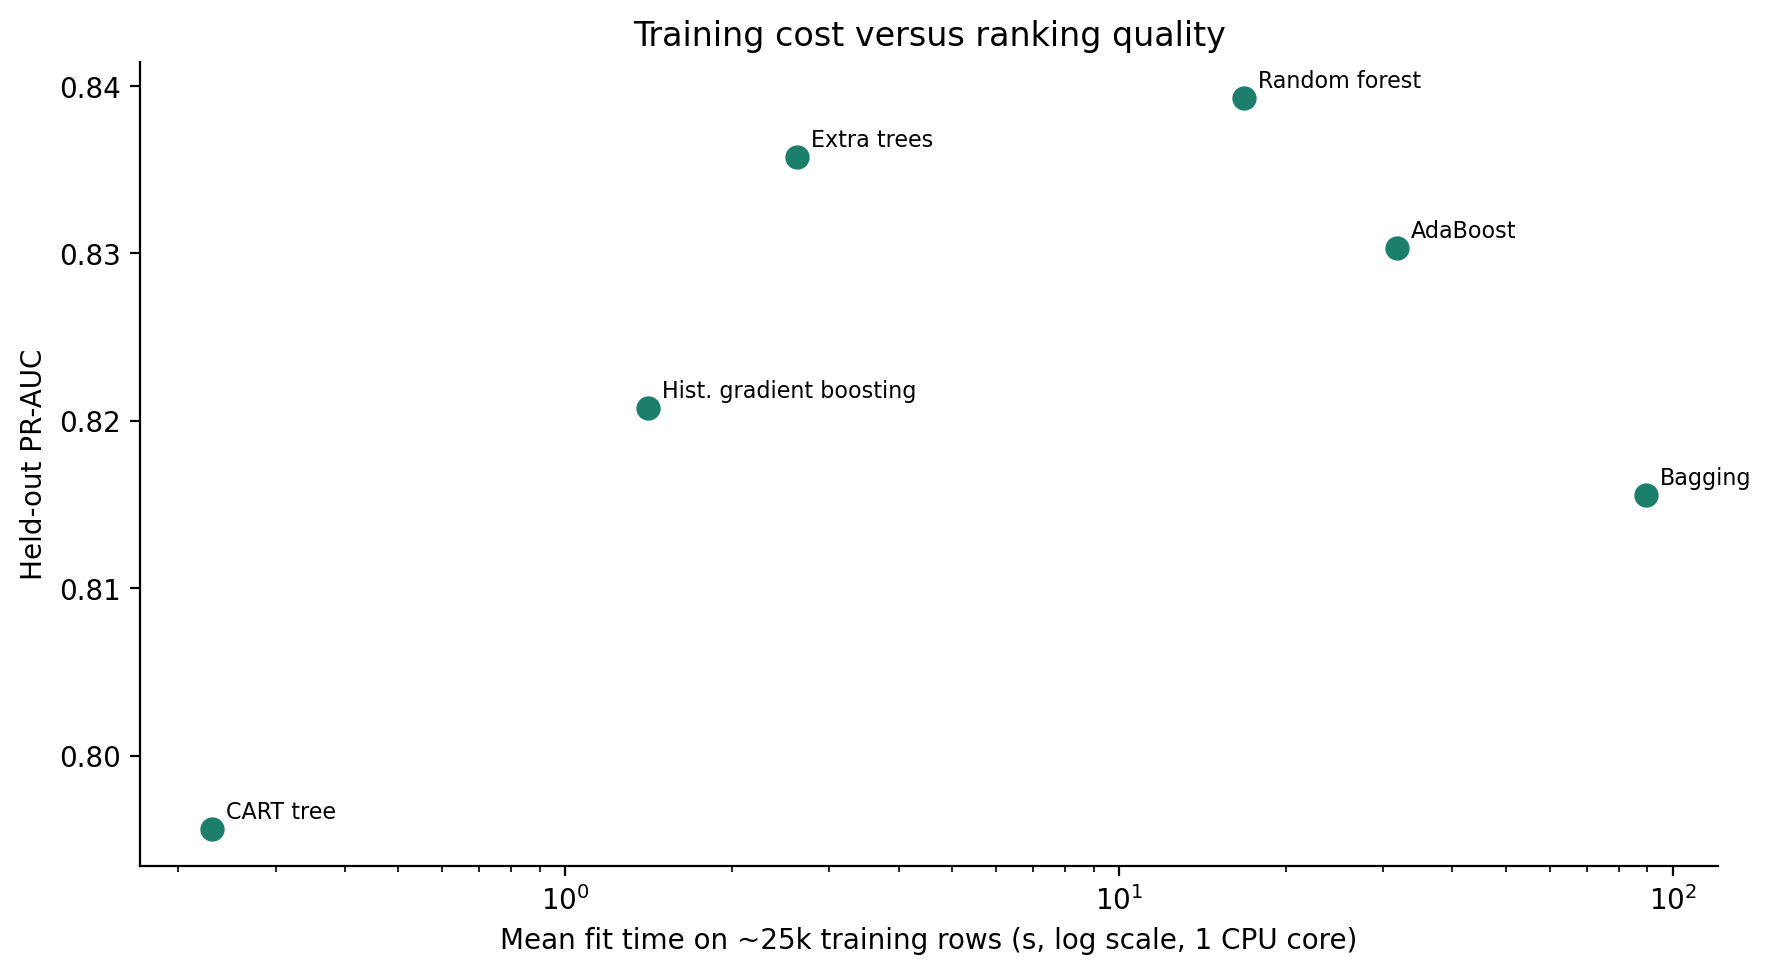

In [12]:
display(pd.read_csv(OUT / 'training_cost.csv'))
display(Image(str(FIG / '11_cost_vs_quality.png'), width=650))

## 4. Result interpretation

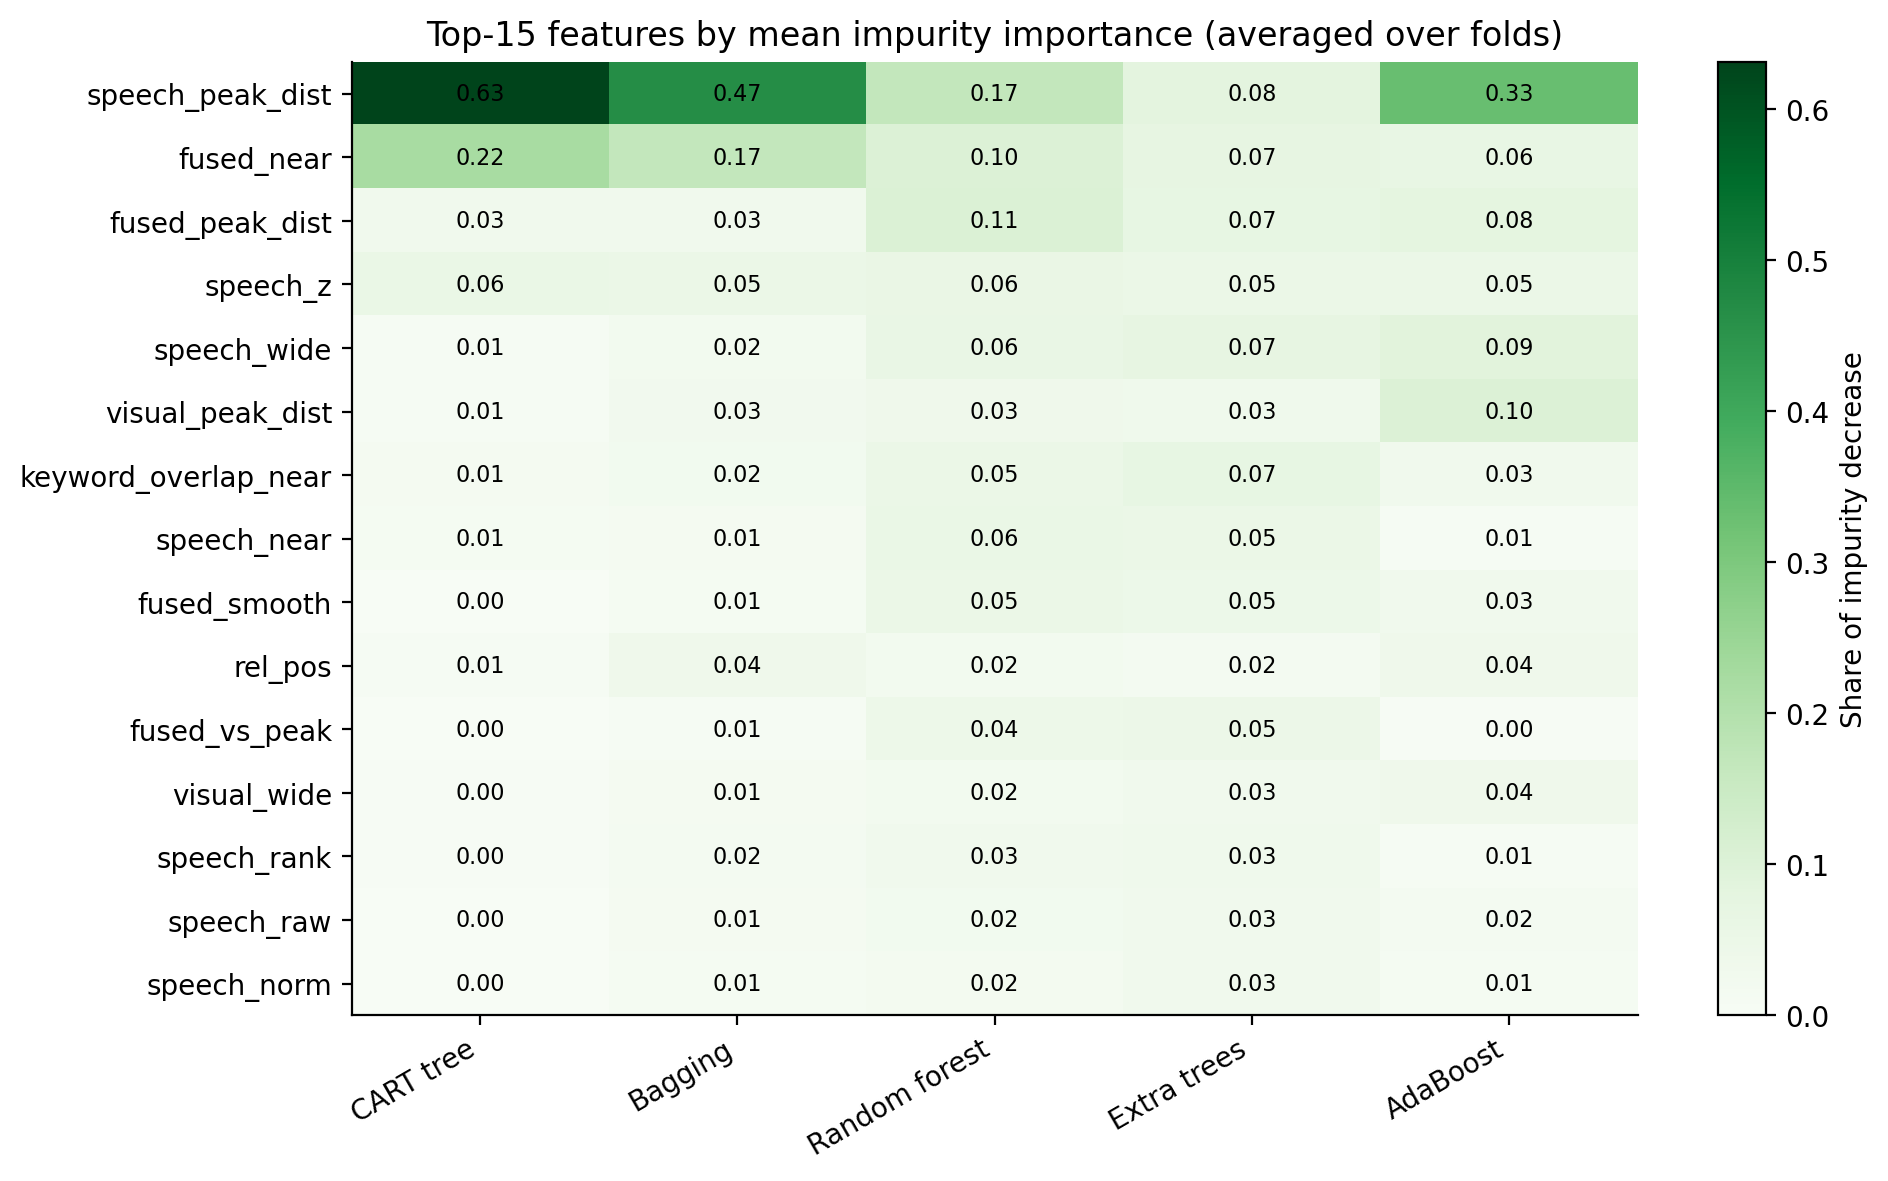

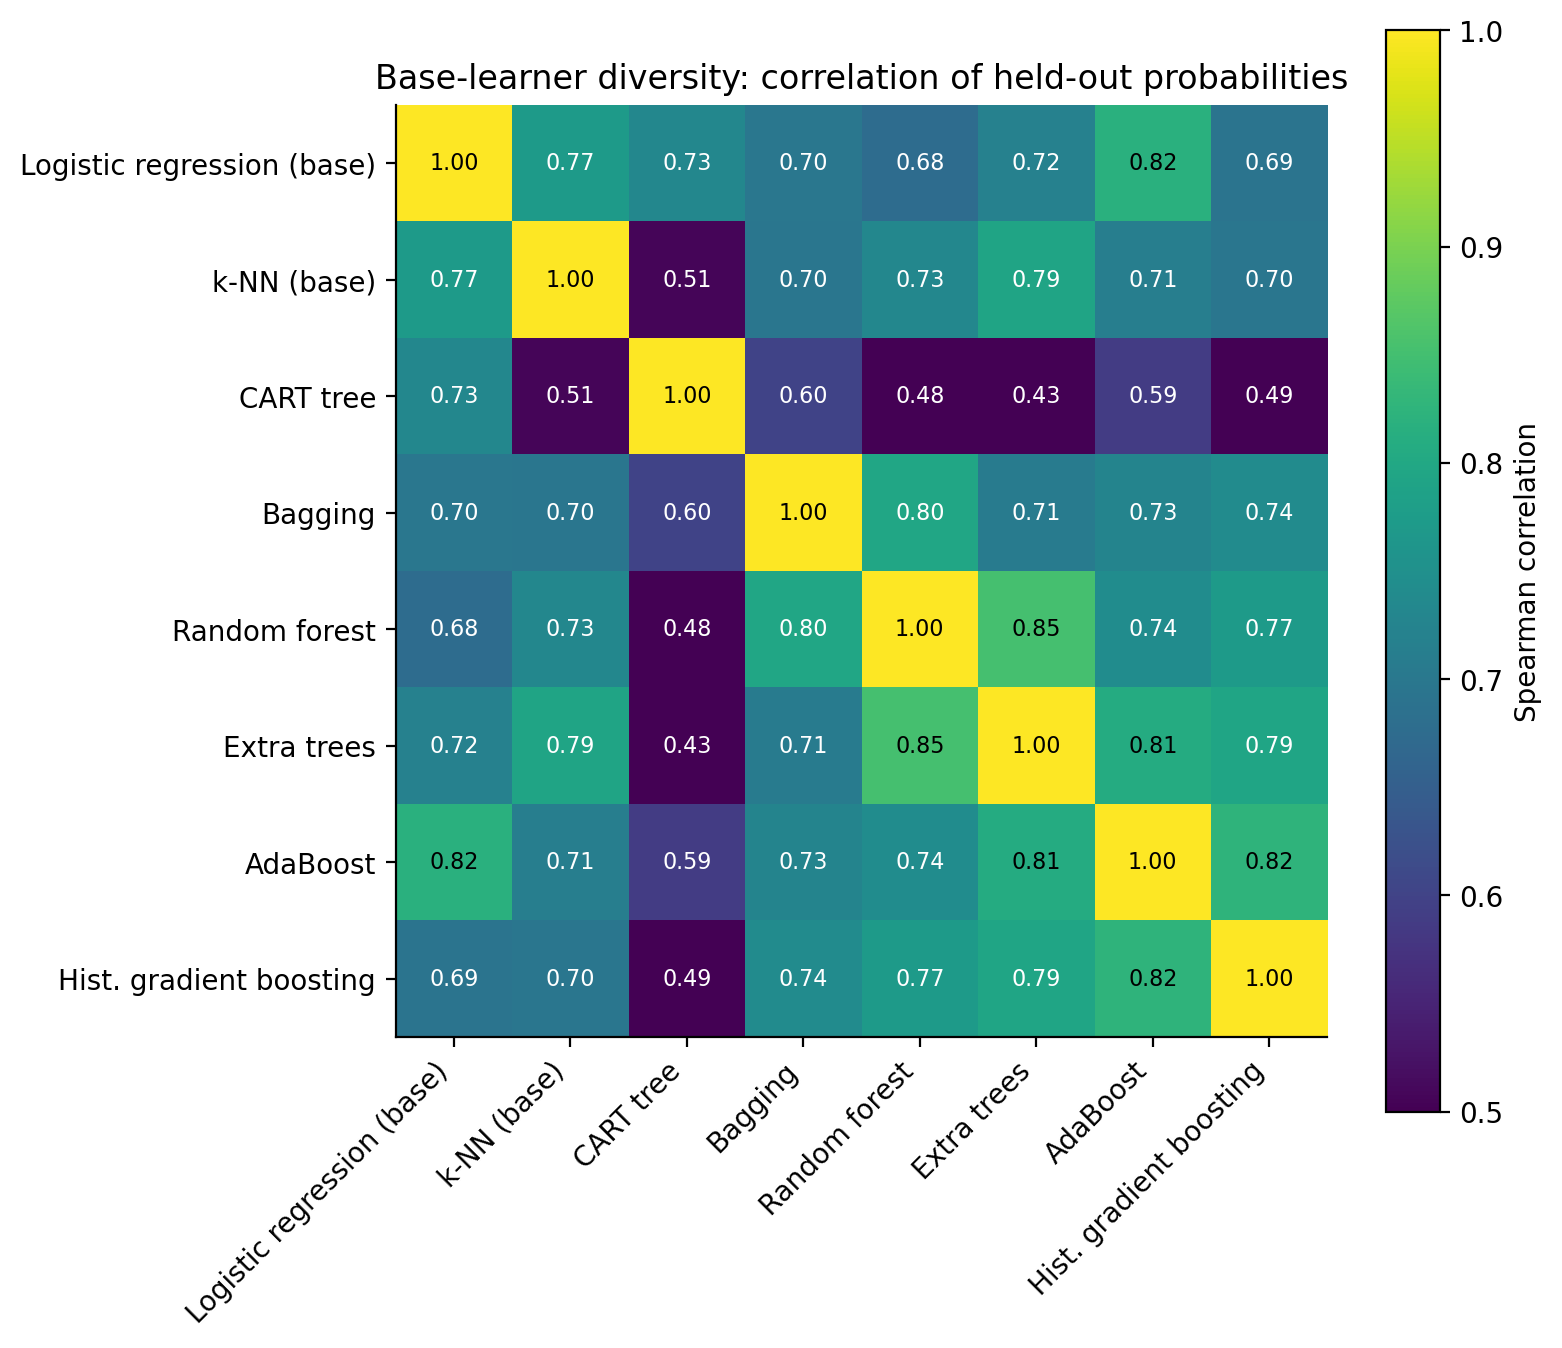

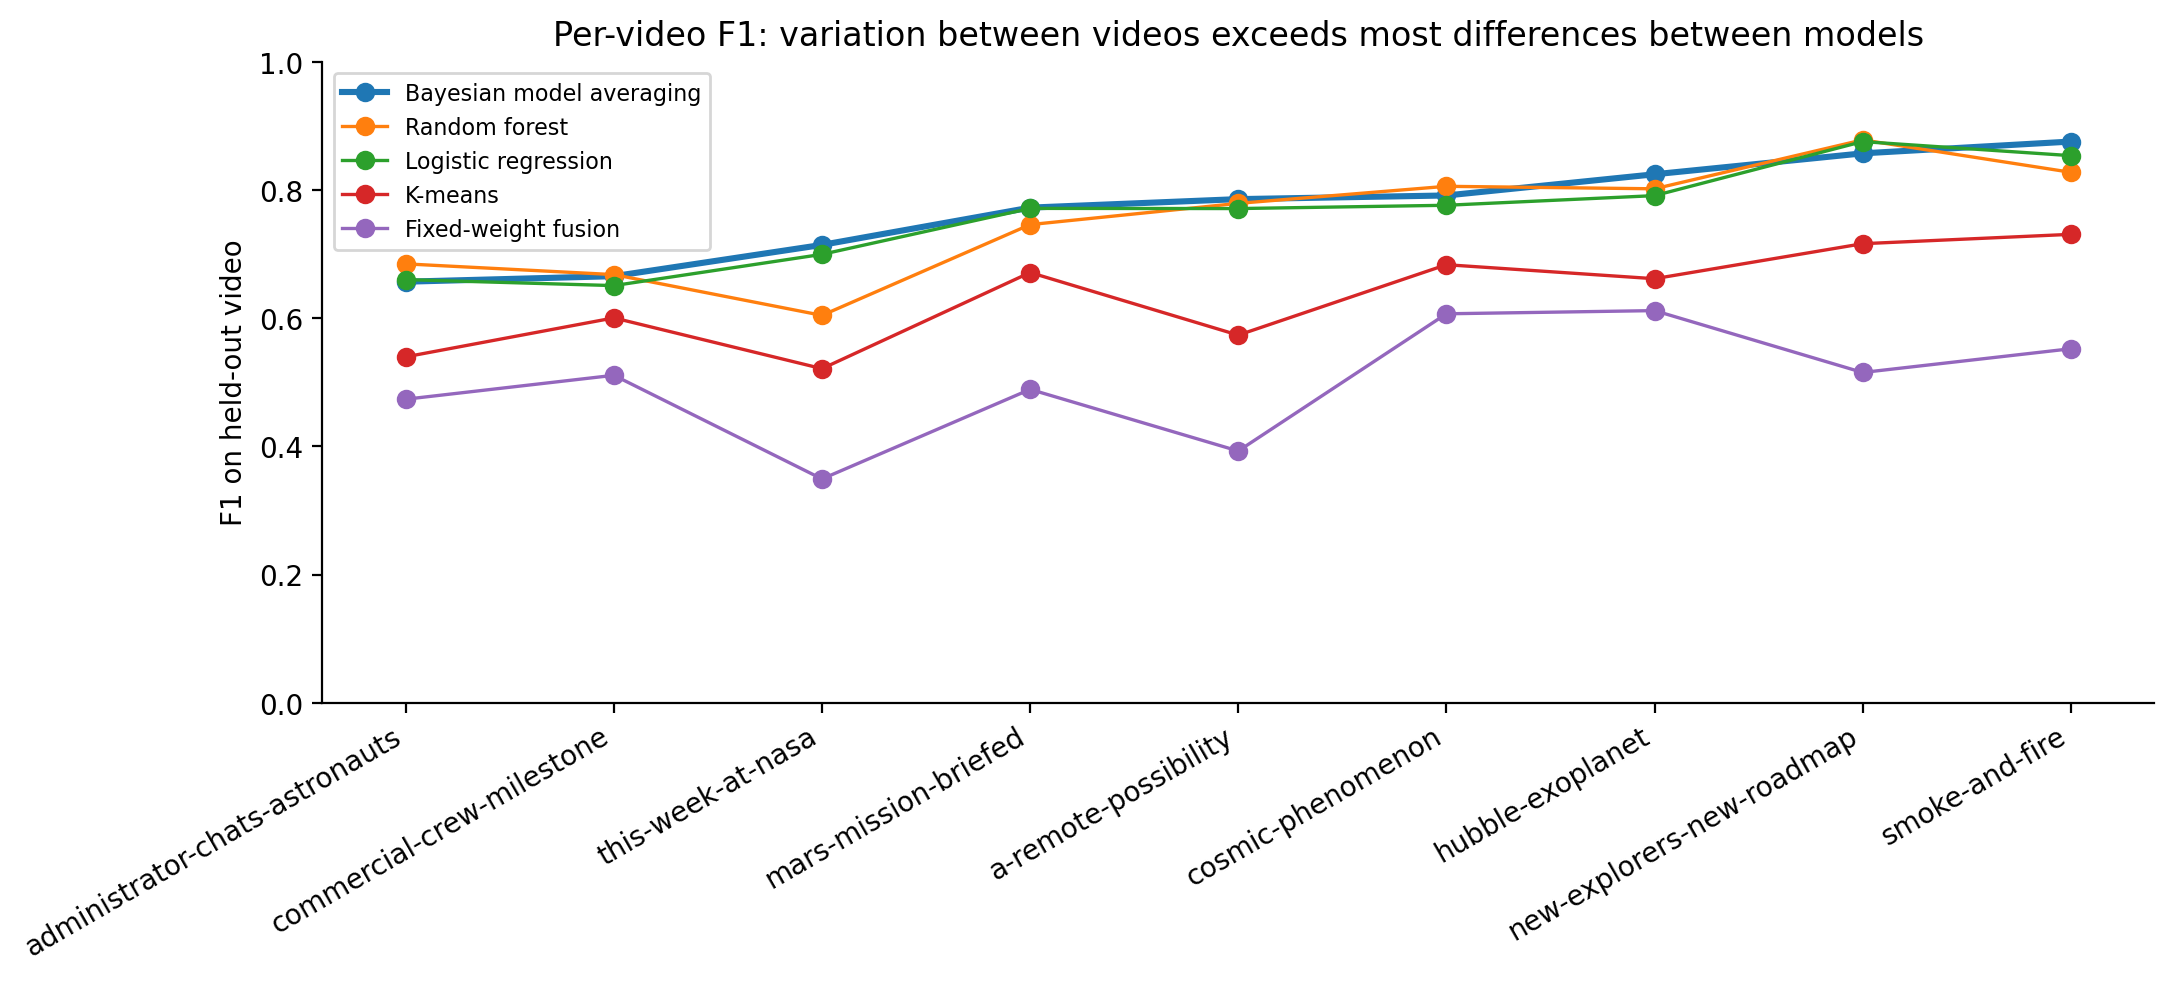

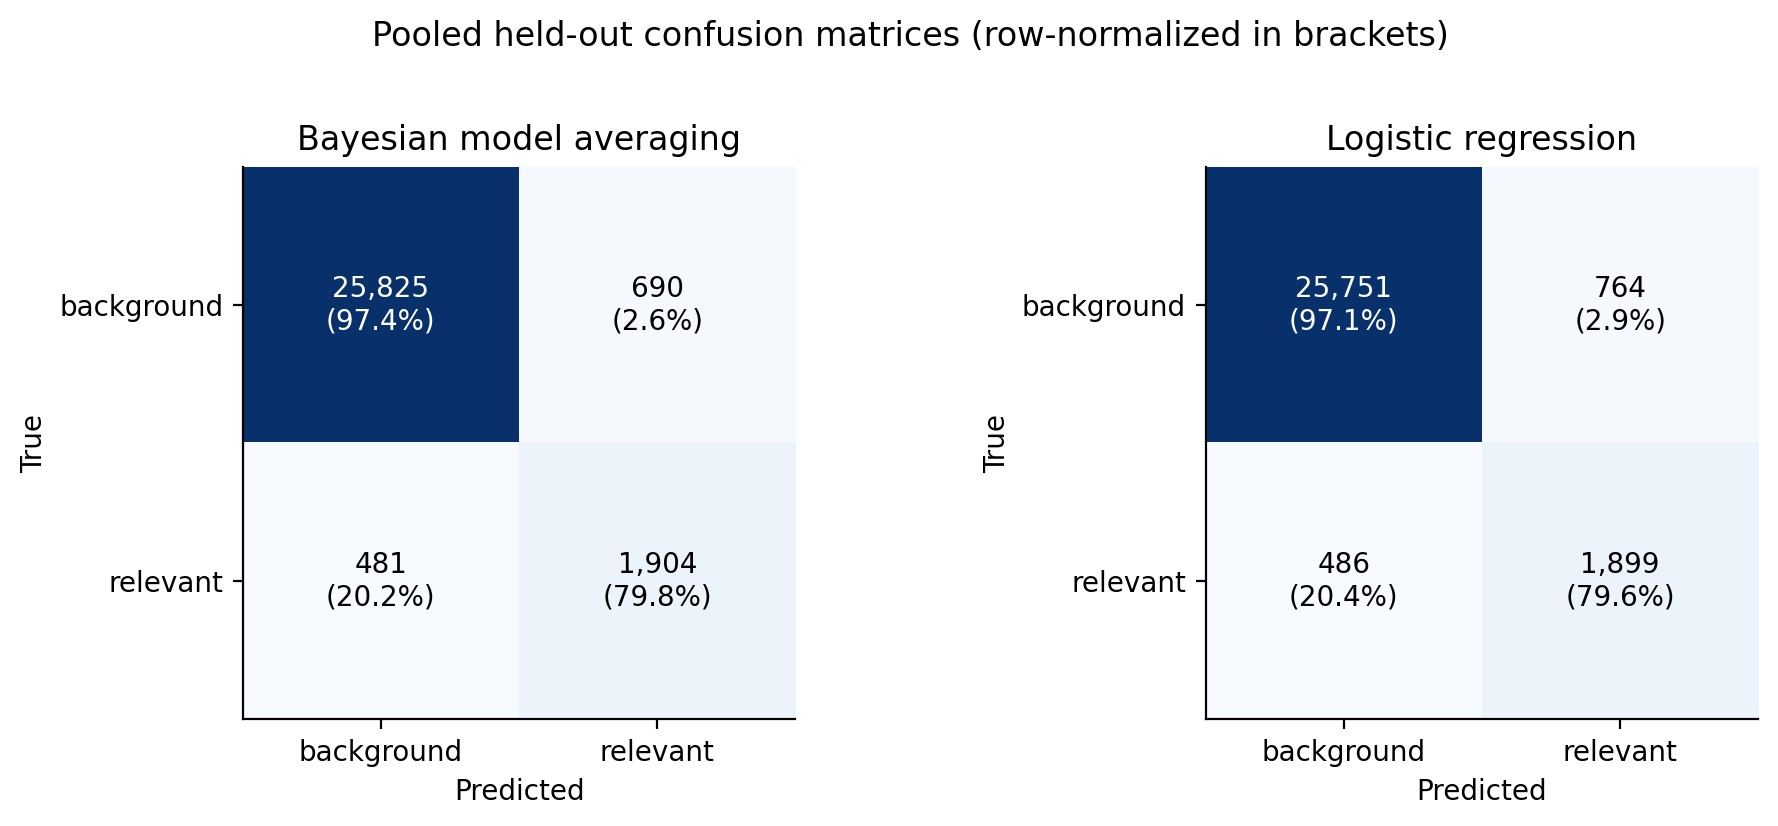

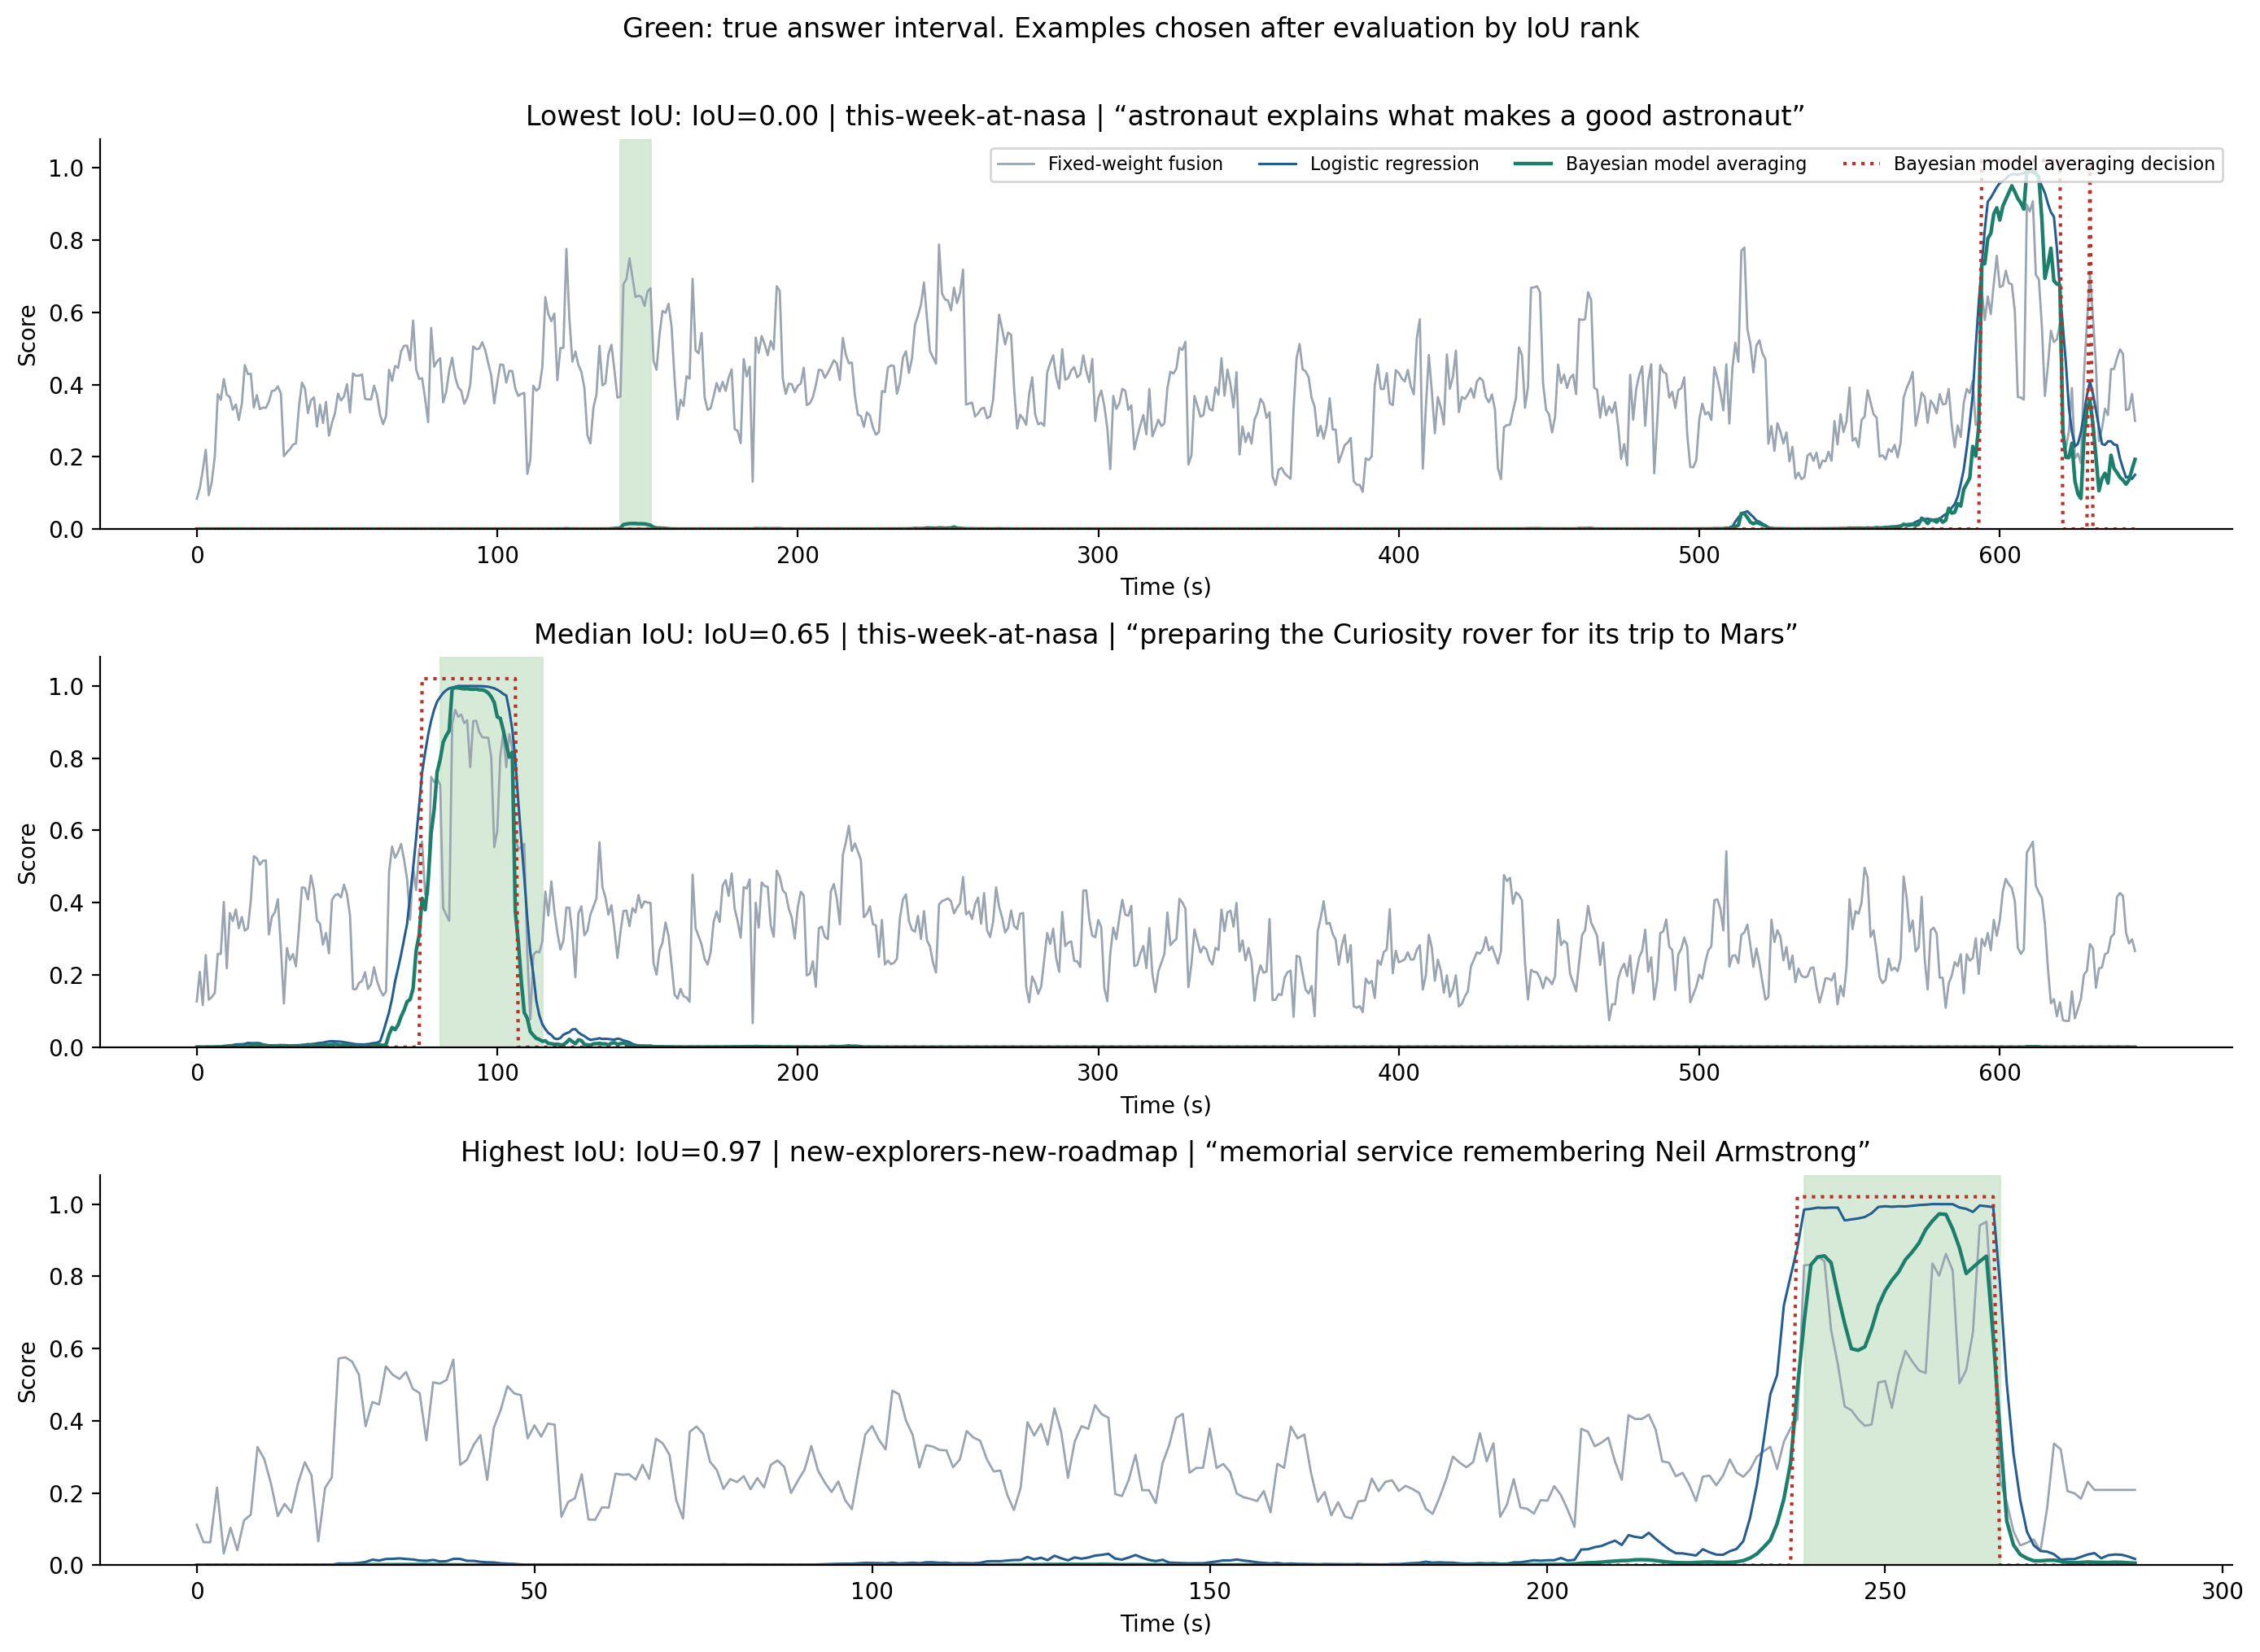

In [13]:
for name in ['07_feature_importance.png', '05_diversity.png', '10_per_video_f1.png', '12_confusion.png', '13_example_timelines.png']:
    display(Image(str(FIG / name), width=900))

In [14]:
s = summary.set_index('method'); best = s.loc[s.index.isin(LEARNERS.values()) | s.index.isin(['Soft voting','Stacking','Bayesian model averaging'])].f1.idxmax()
p = paired[(paired.method == best) & (paired.metric == 'f1')].iloc[0]
display(Markdown(f"**Best ensemble: {best}** — F1 {s.loc[best,'f1']:.3f}, PR-AUC {s.loc[best,'pr_auc']:.3f} "
  f"(logistic regression: {s.loc['Logistic regression','f1']:.3f} / {s.loc['Logistic regression','pr_auc']:.3f}). "
  f"Paired ΔF1 {p.mean_diff:+.3f} [{p.lo:+.3f}, {p.hi:+.3f}], better on {p.videos_better}/9 videos: a small, marginally "
  "significant gain. Homogeneous tree ensembles fix single-tree variance (CART PR-AUC → forests) but do not beat "
  "logistic regression alone; combining a linear model with randomized trees (BMA/stacking/voting) does best."))

**Best ensemble: Bayesian model averaging** — F1 0.771, PR-AUC 0.853 (logistic regression: 0.761 / 0.845). Paired ΔF1 +0.010 [+0.000, +0.020], better on 7/9 videos: a small, marginally significant gain. Homogeneous tree ensembles fix single-tree variance (CART PR-AUC → forests) but do not beat logistic regression alone; combining a linear model with randomized trees (BMA/stacking/voting) does best.